<a href="https://colab.research.google.com/github/mounika1007-m/Laptop-Price-Prediction/blob/main/Laptop_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STEP 1: import libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np
import seaborn as sns

# Visualization
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation
from sklearn.metrics import r2_score, mean_absolute_error#

# STEP 2: load data set

In [2]:
df = pd.read_excel("/content/Laptop_Price_Prediction.xlsx",index_col=0)

# remove index column
if 'Unamed: 0' in df.columns:
 df.drop(columns=['Unnamed: 0'], inplace=True)

df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
Column1,,,,,,,,,,,
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


# STEP 3: Data Understanding








In [3]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   object 
 1   TypeName          1303 non-null   object 
 2   Inches            1303 non-null   float64
 3   ScreenResolution  1303 non-null   object 
 4   Cpu               1303 non-null   object 
 5   Ram               1303 non-null   object 
 6   Memory            1303 non-null   object 
 7   Gpu               1303 non-null   object 
 8   OpSys             1303 non-null   object 
 9   Weight            1303 non-null   object 
 10  Price             1303 non-null   float64
dtypes: float64(2), object(9)
memory usage: 122.2+ KB


,Inches,Price
count,1303.000000,1303.000000
mean,15.017191,59870.042910
std,1.426304,37243.201786
min,10.100000,9270.720000
25%,14.000000,31914.720000
50%,15.600000,52054.560000
75%,15.600000,79274.246400
max,18.400000,324954.720000


In [4]:
#Check missing values
df.isnull().sum()

,0
Company,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0
OpSys,0
Weight,0


# STEP 4: Data Cleaning

In [5]:
#Convert RAM and Weight into numbers
df['Ram'] = df['Ram'].str.replace('GB','')
df['Ram'] = df['Ram'].astype(int)

df['Weight'] = df['Weight'].str.replace('kg','')
df['Weight'] = df['Weight'].astype(float)

# STEP 5: Basic Feature Engineering

In [6]:
#Extract CPU brand
df['Cpu_brand'] = df['Cpu'].apply(lambda x: x.split()[0])

In [7]:
#Check Touchscreen:
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touch' in x else 0)

In [8]:
#Check IPS display:
df['IPS'] = df['ScreenResolution'].apply(lambda x: 1 if 'IPS' in x else 0)

# STEP 6: Exploratory Data Analysis (EDA)

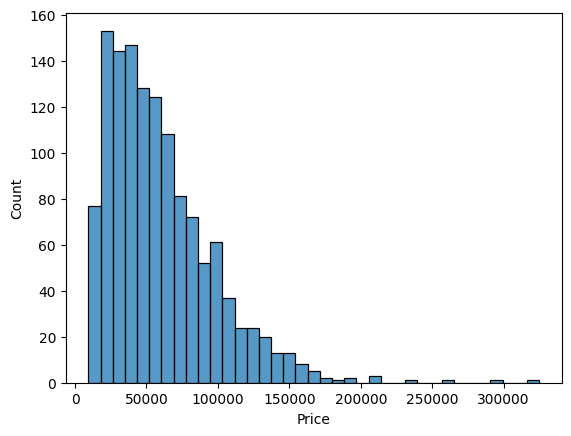

In [9]:
#Price Distribution
sns.histplot(df['Price'])
plt.show()

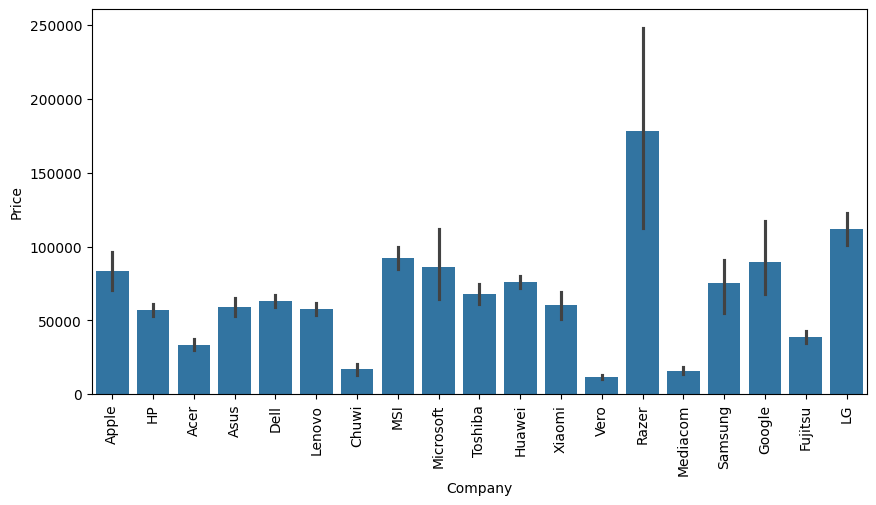

In [10]:
#Company vs Price
plt.figure(figsize=(10,5))
sns.barplot(x=df['Company'], y=df['Price'])
plt.xticks(rotation=90)
plt.show()

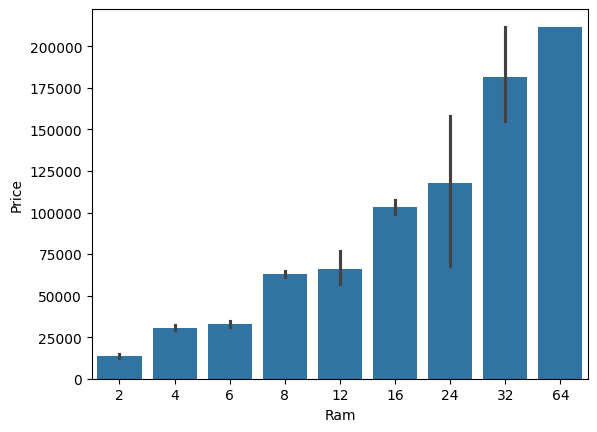

In [11]:
#RAM vs Price
sns.barplot(x=df['Ram'], y=df['Price'])
plt.show()

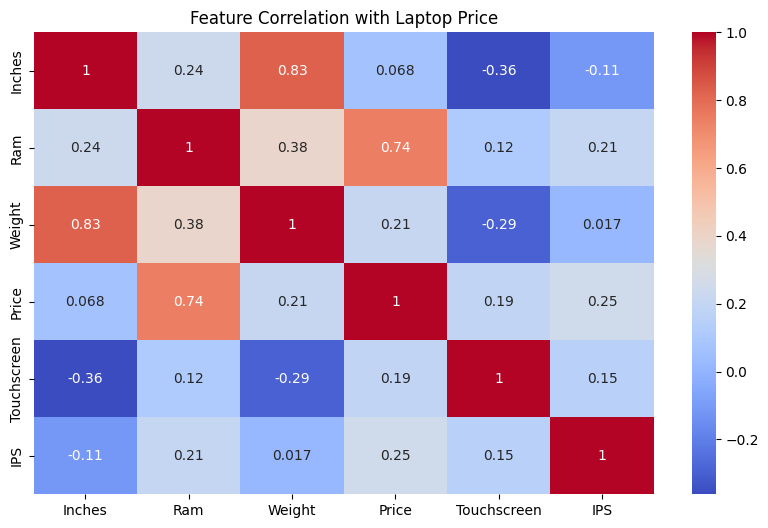

In [12]:
# Correlation Heatmap

numeric_df = df.select_dtypes(include=['int64','float64'])

plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Feature Correlation with Laptop Price")
plt.show()

# STEP 7: Prepare Data for ML

In [13]:
#Drop unnecessary columns:
df.drop(columns=['Cpu','ScreenResolution'], inplace=True)

In [14]:
#Define X and y:
X = df.drop(columns=['Price'])
y = df['Price']

# STEP 8: Train Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# STEP 9: Encoding Categorical Data

In [16]:
#Encoding Categorical Data
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = X.select_dtypes(include='object').columns

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
], remainder='passthrough')

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# STEP 10: Model Comparison

In [18]:
#Linear Regression

lr_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, lr_pred))

Linear Regression R2: 0.8229998361545907


In [19]:
#Decision Tree
dt_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeRegressor())
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree R2:", r2_score(y_test, dt_pred))

Decision Tree R2: 0.710494708047597


In [20]:
#Random Forest
rf_model = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest R2:", r2_score(y_test, rf_pred))
print("MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest R2: 0.7863201105672712
MAE: 10784.798927823522


# STEP 11: Prediction Example

In [21]:
sample = pd.DataFrame({
    'Company':['Dell'],
    'TypeName':['Notebook'],
    'Inches':[15.6],
    'Ram':[8],
    'Memory':['256GB SSD'],
    'Gpu':['Intel HD Graphics'],
    'OpSys':['Windows 10'],
    'Weight':[2.0],
    'Cpu_brand':['Intel'],
    'Touchscreen':[0],
    'IPS':[1]
})

for col in X_train.columns:
    if col not in sample.columns:
        sample[col] = 0

sample = sample[X_train.columns]

predicted_price=rf_model.predict(sample)
print("Predicted Price:",predicted_price[0])

Predicted Price: 62561.281871999985


# STEP 12: Import Pickle

In [22]:
import pickle

# save model
pickle.dump(rf_model, open('laptop_price_model.pkl','wb'))

In [23]:
import gradio as gr

def predict_price(Company, TypeName, Inches, Ram, Memory, Gpu, OpSys, Weight):
    try:
        data = {
            'Company': Company,
            'TypeName': TypeName,
            'Inches': Inches,
            'Ram': Ram,
            'Memory': Memory,
            'Gpu': Gpu,
            'OpSys': OpSys,
            'Weight': Weight,
            'Cpu_brand': 'Intel',
            'Touchscreen': 0,
            'IPS': 0
        }

        sample = pd.DataFrame([data])

        prediction = rf_model.predict(sample)

        return "₹{:,.2f}".format(prediction[0])

    except Exception as e:
        return str(e)

iface = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Textbox(label="Company"),
        gr.Textbox(label="TypeName"),
        gr.Number(label="Inches"),
        gr.Number(label="Ram"),
        gr.Textbox(label="Memory"),
        gr.Textbox(label="Gpu"),
        gr.Textbox(label="Operating System"),
        gr.Number(label="Weight")
    ],
    outputs=gr.Textbox(label="Predicted Laptop Price"),
    title="Laptop Price Predictor"
)

iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d1204fcb400e4178da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Key Insights

* Laptop prices increase significantly with higher RAM capacity, especially above 8GB.
* Apple laptops have higher average prices, while HP, Dell, and Lenovo offer more budget-friendly options.
* High-performance processors (Intel Core i7/i9) contribute to higher laptop prices.
*  IPS displays and high-resolution screens increase pricing due to improved visual quality.
*  Lightweight ultrabooks tend to be more expensive because of portability and premium design.


